# Exploration de la base Postgres — qualité et contenu des données

Notebook d'exploration (pas de logique réutilisable ici — tout ce qui doit
survivre à ce notebook vit dans `src/`, voir `docs/brief_projet.md`).

Objectif : voir concrètement ce qui a été ingéré — colonnes, contenu,
intervalle entre les mesures, et un spectre réel calculé depuis un signal
brut. Toutes les valeurs ci-dessous viennent d'une lecture directe de la
base et des fichiers parquet — rien n'est inventé (discipline "0 mock" du
projet).

**Note sur la base** : le Postgres du projet héberge aussi le backend MLflow
depuis peu (voir `docs/known_issues.md`) — ce notebook filtre explicitement
sur les tables du projet, pas les tables internes MLflow (`runs`, `metrics`,
`experiments`, ...).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import inspect, text

from src.data.db import get_engine
from src.features.fault_frequencies import all_fault_frequencies

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

engine = get_engine()
with engine.connect() as conn:
    who = conn.execute(text("select current_database(), inet_server_addr()")).fetchone()
print(f"Connecté à la base : {who[0]!r} sur {who[1]}")

Connecté à la base : 'vibration' sur 172.27.0.2


## 1. Tables du projet et volumétrie

Liste explicite (pas `\dt` complet) — la base contient aussi les tables
internes MLflow, hors périmètre de cette exploration.

In [2]:
PROJECT_TABLES = [
    "application_type", "site", "zone", "machine", "test_session",
    "bearing_geometry", "asset", "bearing_attributes", "signal",
    "feature", "maintenance_event",
]

rows = []
with engine.connect() as conn:
    for t in PROJECT_TABLES:
        n = conn.execute(text(f'select count(*) from "{t}"')).scalar()
        rows.append({"table": t, "n_lignes": n})

table_counts = pd.DataFrame(rows)
table_counts

,table,n_lignes
0,application_type,6
1,site,0
2,zone,0
3,machine,6
4,test_session,7
5,bearing_geometry,17
6,asset,32
7,bearing_attributes,32
8,signal,7677
9,feature,46062


## 2. Colonnes et contenu, table par table

Pour chaque table : schéma (nom de colonne, type, nullable), un échantillon
réel, et un profil de qualité (taux de remplissage, cardinalité). C'est la
réponse directe à "colonnes et leur contenu".

In [3]:
insp = inspect(engine)

def profile_table(table: str, sample_n: int = 5):
    cols = insp.get_columns(table)
    schema_df = pd.DataFrame(
        [{"colonne": c["name"], "type": str(c["type"]), "nullable": c["nullable"]} for c in cols]
    )
    df = pd.read_sql(f'select * from "{table}"', engine)
    quality = pd.DataFrame({
        "n_non_null": df.notna().sum(),
        "pct_rempli": (df.notna().mean() * 100).round(1),
        "n_valeurs_uniques": df.nunique(),
    })
    return schema_df, df.head(sample_n), quality, len(df)

for _t in PROJECT_TABLES:
    _schema, _sample, _quality, _n = profile_table(_t)
    print(f"\n{'='*90}\n{_t}  ({_n} lignes)\n{'='*90}")
    print("-- schéma --")
    print(_schema.to_string(index=False))
    print("-- qualité (remplissage / cardinalité) --")
    print(_quality.to_string())
    print("-- échantillon --")
    print(_sample.to_string(index=False))


application_type  (6 lignes)
-- schéma --
      colonne    type  nullable
         code VARCHAR     False
        label VARCHAR     False
iso_reference VARCHAR      True
  description VARCHAR      True
-- qualité (remplissage / cardinalité) --
               n_non_null  pct_rempli  n_valeurs_uniques
code                    6       100.0                  6
label                   6       100.0                  6
iso_reference           5        83.3                  1
description             6       100.0                  6
-- échantillon --
                  code                          label iso_reference                                               description
        electric_motor Moteur / generateur electrique   ISO 20816-3           Moteurs a induction ou synchrones, generateurs.
      centrifugal_pump               Pompe centrifuge   ISO 20816-3                         Pompes centrifuges industrielles.
            fan_blower       Ventilateur / soufflante   ISO 20816-3       

## 3. Intervalle entre les mesures

Deux échelles de temps distinctes dans ce dataset, à ne pas confondre :

- **à l'intérieur d'un signal** — l'écart entre échantillons bruts, fixé par
  la fréquence d'échantillonnage (`sampling_rate_hz` dans `signal`)
- **entre deux acquisitions successives** — l'écart entre deux mesures
  distinctes d'un même roulement (horodatage réel dans `feature.timestamp`,
  pas un artefact de calcul)

In [4]:
# 3a. Intervalle intra-signal (echantillonnage brut)
sampling = pd.read_sql(
    """
    select channel, sampling_rate_hz, count(*) as n_signaux,
           round((1.0/sampling_rate_hz)::numeric, 8) as intervalle_s
    from signal
    group by channel, sampling_rate_hz
    order by channel
    """,
    engine,
)
sampling

,channel,sampling_rate_hz,n_signaux,intervalle_s
0,current_1,64000.0,2559,0.000016
1,current_2,64000.0,2559,0.000016
2,vibration,64000.0,2559,0.000016


In [5]:
# 3b. Intervalle entre acquisitions successives (mêmes roulement/canal)
# distinct sur timestamp : plusieurs features (rms, kurtosis, ...) partagent
# le même timestamp d'acquisition, on ne veut compter chaque mesure qu'une fois.
ts = pd.read_sql(
    """
    select distinct asset_id, channel, timestamp
    from feature
    where channel = 'vibration'
    order by asset_id, timestamp
    """,
    engine,
)
ts["timestamp"] = pd.to_datetime(ts["timestamp"])
ts["delta_s"] = ts.groupby("asset_id")["timestamp"].diff().dt.total_seconds()

deltas = ts["delta_s"].dropna()
print(f"{len(deltas)} intervalles calculés sur {ts['asset_id'].nunique()} assets")
print(deltas.describe())

# Bimodal attendu : quelques dizaines de secondes au sein d'une session
# d'essai, contre des mois d'écart entre roulements différents (voir
# docs/known_issues.md, "confusion date d'essai / asset / defect_origin").
within_session = deltas[deltas < 3600]
between_session = deltas[deltas >= 3600]
print(f"\nIntra-session (< 1h) : {len(within_session)} intervalles, médiane {within_session.median():.1f}s")
print(f"Inter-session (>= 1h) : {len(between_session)} intervalles, médiane {between_session.median()/86400:.1f} jours")

2523 intervalles calculés sur 32 assets
count     2523.000000
mean        89.523187
std       1487.859752
min         19.000000
25%         28.000000
50%         34.000000
75%         59.000000
max      74526.000000
Name: delta_s, dtype: float64

Intra-session (< 1h) : 2521 intervalles, médiane 34.0s
Inter-session (>= 1h) : 2 intervalles, médiane 0.5 jours


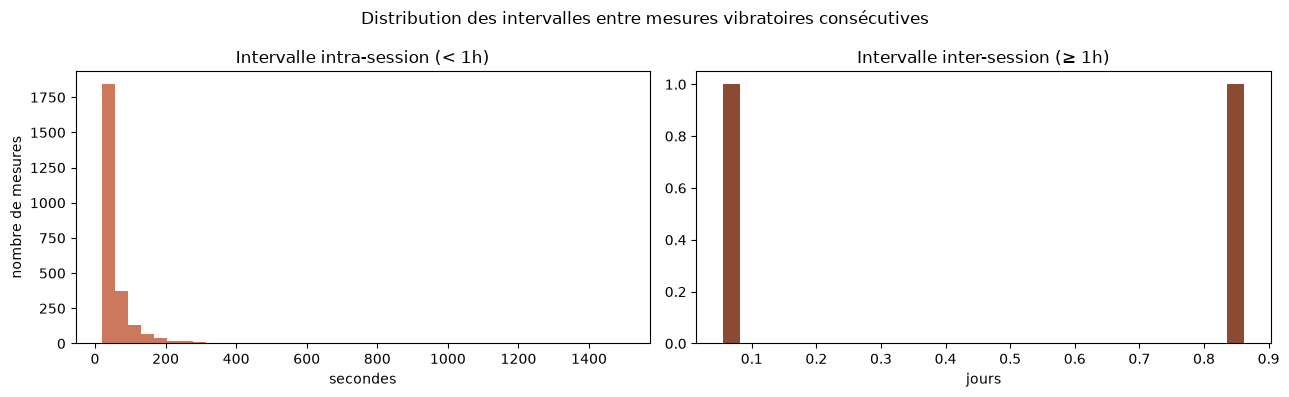

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(within_session, bins=40, color="#CC785C", edgecolor="none")
axes[0].set_title("Intervalle intra-session (< 1h)")
axes[0].set_xlabel("secondes")
axes[0].set_ylabel("nombre de mesures")

axes[1].hist(between_session / 86400, bins=30, color="#8C4A32", edgecolor="none")
axes[1].set_title("Intervalle inter-session (≥ 1h)")
axes[1].set_xlabel("jours")

fig.suptitle("Distribution des intervalles entre mesures vibratoires consécutives")
fig.tight_layout()
plt.show()

## 4. Spectre d'un signal mesuré

Chargement d'un vrai fichier parquet (pas une simulation), FFT du signal
brut, et repère des fréquences caractéristiques **théoriques** (BPFO/BPFI/
BSF/FTF) calculées depuis la géométrie réelle du roulement et la vitesse de
la condition d'essai.

**Attention à l'interprétation** : ces raies ne sont pas nécessairement
visibles dans le spectre **brut** — c'est précisément pour ça que le projet
utilise l'analyse d'enveloppe (voir `docs/theorie_reference.md` §3, et
`docs/known_issues.md` pour l'état de fiabilisation du kurtogramme). Les
lignes verticales sont une référence de calcul, pas une détection.

In [7]:
sig_row = pd.read_sql(
    """
    select s.id, s.asset_id, s.file_path, s.sampling_rate_hz, s.n_samples,
           a.code, a.health_state, ts.rotational_speed_rpm, ts.label as condition
    from signal s
    join asset a on a.id = s.asset_id
    join test_session ts on ts.id = s.test_session_id
    where s.channel = 'vibration'
    order by s.asset_id, s.measurement_index
    limit 1
    """,
    engine,
).iloc[0]
sig_row

id                                                                   7680
asset_id                                          paderborn_kat_rig::K001
file_path               /app/data/processed/paderborn/K001/N09_M07_F10...
sampling_rate_hz                                                  64000.0
n_samples                                                          256823
code                                                                 K001
health_state                                                      healthy
rotational_speed_rpm                                                900.0
condition                                                     N09_M07_F10
Name: 0, dtype: object

In [8]:
arr = pd.read_parquet(sig_row["file_path"])["vibration"].to_numpy()
fs = sig_row["sampling_rate_hz"]
n = len(arr)

freqs = np.fft.rfftfreq(n, d=1 / fs)
spectrum = np.abs(np.fft.rfft(arr)) / n

# geometrie reelle du roulement + vitesse de la condition -> frequences theoriques
geo = pd.read_sql(
    """
    select bg.n_balls, bg.ball_diameter_mm, bg.pitch_diameter_mm, bg.contact_angle_deg
    from bearing_attributes ba
    join bearing_geometry bg on bg.model = ba.geometry_model
    where ba.asset_id = %(aid)s
    """,
    engine,
    params={"aid": sig_row["asset_id"]},
)

theo_freqs = {}
if not geo.empty and sig_row["rotational_speed_rpm"]:
    g = geo.iloc[0]
    theo_freqs = all_fault_frequencies(
        int(g["n_balls"]), sig_row["rotational_speed_rpm"],
        g["ball_diameter_mm"], g["pitch_diameter_mm"], g["contact_angle_deg"] or 0.0,
    )
theo_freqs

{'BPFO': np.float64(46.05851979345955),
 'BPFI': np.float64(73.94148020654045),
 'BSF': np.float64(30.535092751960224),
 'FTF': np.float64(5.757314974182444)}

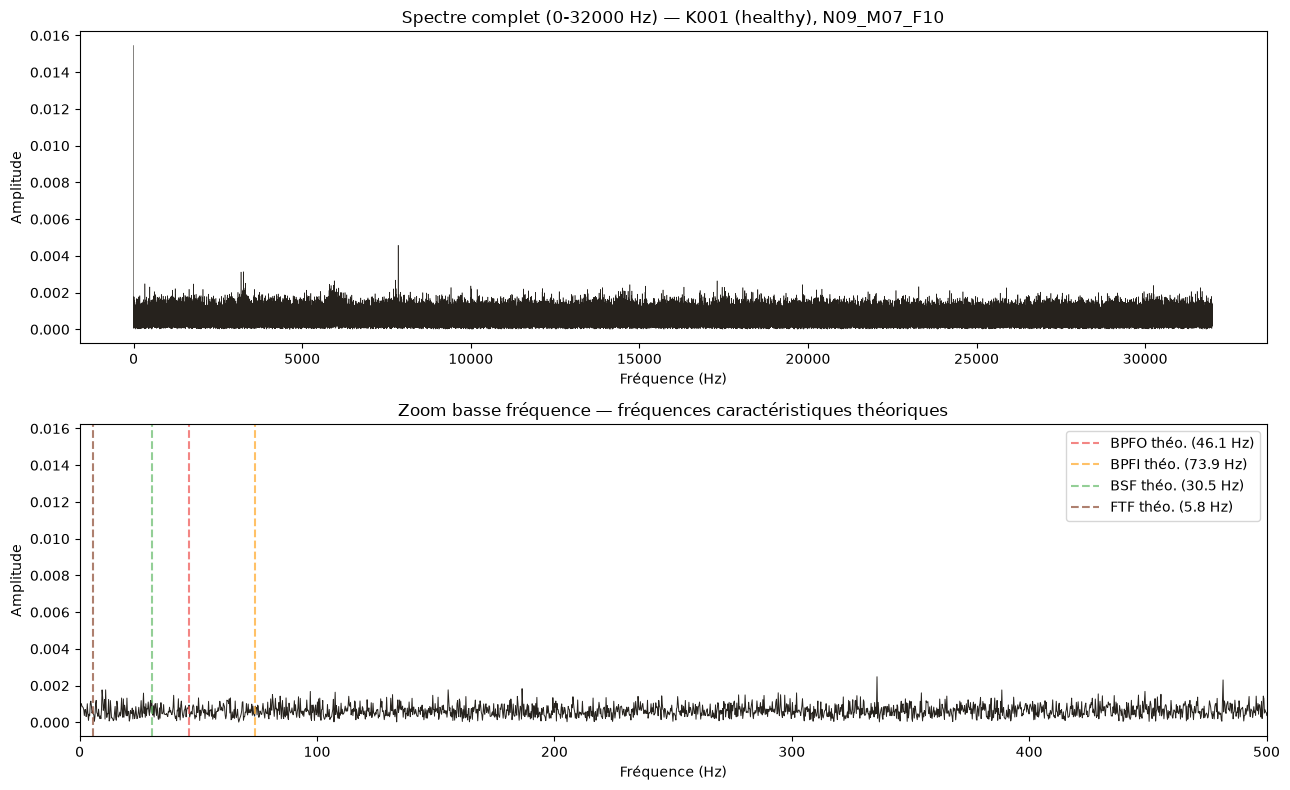

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8))

axes[0].plot(freqs, spectrum, linewidth=0.4, color="#26221D")
axes[0].set_title(f"Spectre complet (0-{fs/2:.0f} Hz) — {sig_row['code']} ({sig_row['health_state']}), {sig_row['condition']}")
axes[0].set_xlabel("Fréquence (Hz)")
axes[0].set_ylabel("Amplitude")

axes[1].plot(freqs, spectrum, linewidth=0.7, color="#26221D")
axes[1].set_xlim(0, 500)
axes[1].set_title("Zoom basse fréquence — fréquences caractéristiques théoriques")
axes[1].set_xlabel("Fréquence (Hz)")
axes[1].set_ylabel("Amplitude")

colors = {"BPFO": "#EF5350", "BPFI": "#FFA726", "BSF": "#66BB6A", "FTF": "#8C4A32"}
for name, f in theo_freqs.items():
    axes[1].axvline(f, color=colors.get(name, "gray"), linestyle="--", alpha=0.7, label=f"{name} théo. ({f:.1f} Hz)")
if theo_freqs:
    axes[1].legend()

fig.tight_layout()
plt.show()

## 5. Bilan qualité

Synthèse des points de vigilance déjà identifiés sur ce dataset — pour le
détail et les hypothèses, voir `docs/known_issues.md`.

In [10]:
print("=== Bilan qualité — lecture directe de la base ===\n")

print(f"Tables projet : {len(PROJECT_TABLES)}, {table_counts['n_lignes'].sum()} lignes au total\n")

health = pd.read_sql("select health_state, count(*) as n from asset group by health_state order by n desc", engine)
print("Répartition health_state (asset) :")
print(health.to_string(index=False))

origin = pd.read_sql(
    "select coalesce(defect_origin,'NULL') as defect_origin, count(*) as n from bearing_attributes group by defect_origin order by n desc",
    engine,
)
print("\nRépartition defect_origin (bearing_attributes) :")
print(origin.to_string(index=False))

unit_conf = pd.read_sql(
    "select coalesce(unit_confidence,'NULL') as unit_confidence, count(*) as n from signal group by unit_confidence order by n desc",
    engine,
)
print("\nConfiance sur l'unité du signal brut (signal.unit_confidence) :")
print(unit_conf.to_string(index=False))

date_range = pd.read_sql("select min(timestamp) as debut, max(timestamp) as fin from feature", engine)
print(f"\nPlage temporelle des mesures (feature.timestamp) : {date_range['debut'].iloc[0]} → {date_range['fin'].iloc[0]}")

print(
    "\nPoints de vigilance déjà documentés (docs/known_issues.md) :"
    "\n  - chaque asset est testé sur un seul jour calendaire : asset_id, date"
    "\n    d'essai et defect_origin sont largement confondus"
    "\n  - kurtogramme (bande de résonance pour l'enveloppe) en cours de"
    "\n    fiabilisation, features BPFO/BPFI/BSF/FTF pas encore activées par défaut"
)

=== Bilan qualité — lecture directe de la base ===

Tables projet : 11, 53839 lignes au total

Répartition health_state (asset) :
health_state  n
      faulty 26
     healthy  6

Répartition defect_origin (bearing_attributes) :
defect_origin  n
         real 14
   artificial 12
           na  6

Confiance sur l'unité du signal brut (signal.unit_confidence) :
unit_confidence    n
       inferred 7677

Plage temporelle des mesures (feature.timestamp) : 2014-06-04 10:49:59 → 2015-10-16 17:53:27

Points de vigilance déjà documentés (docs/known_issues.md) :
  - chaque asset est testé sur un seul jour calendaire : asset_id, date
    d'essai et defect_origin sont largement confondus
  - kurtogramme (bande de résonance pour l'enveloppe) en cours de
    fiabilisation, features BPFO/BPFI/BSF/FTF pas encore activées par défaut
